# LeetCode #139: Word Break

https://leetcode.com/problems/word-break/

## Three ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute force: try every way to split** | $O(2^n)$ | $O(n)$ | `"aaa…ab"` with words `a`, `aa`, `aaa`… tries an astronomical number of splits before failing. |
| **Recursion that remembers each suffix's answer** | $O(n^3)$ | $O(n)$ | Fast enough, but up to 300 nested calls. |
| **A table of reachable cuts, filled left to right ★** | $O(n^3)$ | $O(n)$ | About 45,000 (start, end) pairs at most for 300 letters, each a short substring lookup. |

`n` is the length of `s` (at most 300). There are about $n^2/2$ pairs of cut points, and each check
copies and hashes a piece of up to `n` letters, which is where $O(n^3)$ comes from: at most about 4.5
million letter operations for $n = 300$, well under a second. $O(n)$ space is one True/False box per cut.
$O(2^n)$ means each extra letter can double the work.

A **cut** is a position between letters. Cut `i` sits after the first `i` letters; cut 0 is the very
start. The string **splits** if it can be chopped at some cuts so that every piece is a dictionary word
(words may be reused).

## Understanding the methods

### Brute force

Take any dictionary word that the string starts with, then recurse on what's left. The same leftover
suffix is reached by many different routes and solved again every time, so failing inputs blow up.

### Recursion that remembers each suffix's answer

The same recursion, but store "can this suffix split?" the first time it's worked out. Each suffix is then
solved once. It works, but the calls nest as deep as the string is long.

### Optimal: a table of reachable cuts, filled left to right ★ (the one coded below)

`dp[i]` answers "can the first `i` letters split into words?". `dp[0]` is True (nothing to split). Cut
`i` is reachable if some earlier reachable cut `j` is followed by a word `s[j:i]`. Fill the boxes from left
to right and read `dp[n]`. Building each answer from smaller stored ones is **dynamic programming**.

**Why this beats the recursive version:** the same checks without any recursion, so there's no call
stack to overflow, and it stops searching for each cut at the first route that works.

**Constraints:**
* `1 <= s.length <= 300`
* `1 <= wordDict.length <= 1000`
* `1 <= wordDict[i].length <= 20`
* `s` and `wordDict[i]` consist of only lowercase English letters
* All the strings of `wordDict` are unique


## Explain Like I'm a Newbie

### What the question is actually asking

Can you put spaces into `s` so that every piece is a word from the list? Words can be used more than once.

```
"leetcode"   -> "leet code"           yes
"catsandog"  -> "cats and og"         no: "og" isn't a word
                "cat sand og"         no
```

### The one idea you need: think about cuts, not words

The tempting approach is greedy: grab the longest word the string starts with, then repeat. It's wrong,
because an early choice can strand you. With `["car", "ca", "rs"]`, `"cars"` greedily becomes `car` + `s`
and fails, though `ca` + `rs` works.

So don't commit to choices. Instead, ask about every **cut** (a position between letters):

> **`dp[i]` = True if the first `i` letters can be split into words.**

Cut 0, before any letters, is always True: there's nothing to split. Then cut `i` is True exactly when
there's some earlier True cut `j` and the piece between them, `s[j:i]`, is a word. Whatever happened before
cut `j` doesn't matter any more; `dp[j]` already says it worked. Fill the boxes left to right and the
answer is the last one, `dp[n]`.

### What that means in code

A list `dp` of `n + 1` booleans, `dp[0] = True`. For each `i`, try every `j` below it; if `dp[j]` is True
and `s[j:i]` is in a set of the words, mark `dp[i]` True and stop looking (one route is enough). Putting
the words in a set makes each "is this a word?" check a quick lookup instead of a scan through 1,000
words. Building answers from smaller stored answers is **dynamic programming**.

### Mistakes people make the first time

1. **Greedy longest match.** It passes all three of LeetCode's samples, then returns false on `"cars"`
   with `["car","ca","rs"]`.
2. **Forgetting to check `dp[j]`.** Then `"dog"` ending `"catsandog"` marks the end True, and the third
   sample wrongly returns true.
3. **Plain recursion with no memory.** Correct, but `"aaa…ab"` with words `a`, `aa`, `aaa`… re-solves the
   same suffixes until it times out. LeetCode has exactly that test.

### Things worth knowing

Words are at most 20 letters, so `j` only needs to go back 20 places from `i`. The posted code doesn't use
that, and still runs well inside the limits.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Let dp[i] say whether the first i letters can be split into words. dp[0] is true, because the empty prefix needs no words. Cut i is reachable if some earlier reachable cut j is followed by a dictionary word s[j:i]. I fill that left to right with the words in a hash set and return dp[n]. There are about n squared over two pairs to check, each a substring lookup. It never recurses, so depth isn't a problem; the obvious improvement is to only look back as far as the longest word."

That's the meaning of a cell, the base case, the transition and the cost, plus the one optimisation I'd ask about. Good start.

---

### I slide the problem across the table

I write `s = "catsandog"`, `wordDict = ["cats","dog","sand","and","cat"]`.

> **You:** "Can I reuse a word? And do I need the actual split, or just yes or no?"

**"Reuse is fine. Just true or false."** Both answers matter. Reuse means I'm not tracking which words are used up, and yes-or-no means a boolean per cut is enough. If I'd said "return every split", that's Word Break II and the output alone can be exponential.

> **You:** "How long can things get?"

**"s up to 300, up to 1,000 words, each up to 20 letters."** Good: that 20 is going to matter, and I'm glad you asked.

---

### Now tell me what's actually hard about it

> **You:** "The first idea is greedy: peel off a word, keep going. But a choice early on can strand me. With 'cars' and the words 'car', 'ca', 'rs', taking 'car' leaves an 's' that's not a word, though 'ca' plus 'rs' works. So I'd have to backtrack, and backtracking re-solves the same leftovers over and over. 'aaaa…ab' with a, aa, aaa makes that explode."

> **You:** "The thing that saves me: once I know the first j letters split somehow, I don't care how. Only the position matters. So there are only n + 1 states, one per cut."

That's the hard part named, and named with an input. The jump from "the route doesn't matter, only the position" to a table of n + 1 booleans is the whole technique, and you got there without saying "DP" first.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "dp has n + 1 booleans, dp[0] true. For i from 1 to n, for j from 0 to i − 1: if dp[j] and s[j:i] is in the set, dp[i] is true, break.
>
> That's about n squared over two pairs, 45,000 for 300 letters. Each check slices and hashes up to n letters, so strictly it's O(n cubed) letter work, a few million operations at the limit. Memory is the table plus the word set."

I'll take O(n²) lookups as long as you can tell me what a lookup costs. Candidates who say "O(n²)" and stop usually haven't thought about the substring.

---

### Now whiteboard it

```
word_set = set(wordDict)
dp = [False] * (n + 1)
dp[0] = True
```

> **You:** "The set turns 'is this a word?' into one hash lookup instead of scanning a thousand words. dp[0] is true because the empty prefix is trivially split; without it nothing can ever become true."

If you start dp[0] at false and don't notice, everything returns false, and I'll ask you to run `"a"`.

```
for i in range(1, n + 1):
    for j in range(i):
        if dp[j] and s[j:i] in word_set:
            dp[i] = True
            break
return dp[n]
```

> **You:** "The dp[j] check comes first, so I don't even slice when cut j isn't reachable. And I break on the first route because I only need to know cut i is reachable, not how many ways."

That dp[j] is the line I'm watching. Without it, `"catsandog"` returns true, because `"dog"` is a word ending at the last cut, and nothing checks that `"catsan"` splits.

Sometimes I ask what happens if the `break` goes.

> **You:** "Still correct, just slower. dp[i] only ever goes from false to true, so finding a second route changes nothing. The break just saves the remaining lookups for that cut, which matters most on long strings full of short words."

---

### Walk me through it before you say you're done

> **You:** "dp[0] true. Cut 3: 'cat', true. Cut 4: 'cats', true. Cuts 5 and 6: nothing from 0, 3 or 4 is a word. Cut 7: from 3, 'sand' is a word, true. Cut 8: 'catsando', 'sando', 'ando', 'o', none. Cut 9: from 7 it's 'og', from 4 'andog', from 3 'sandog', from 0 the whole thing. None. False."

> **You:** "And reuse, from your first answer: 'applepenapple' uses 'apple' twice, which is fine, because the set doesn't get used up."

Tying it back to the clarifier is exactly what I want.

---

### Then tell me where it breaks, before I ask

> **You:** "Nothing breaks inside these limits. What it leans on is that pieces are short, and it doesn't use that. Words are at most 20 letters, so j only needs to start at i − 20. That turns 45,000 pairs into about 6,000 and takes the cube out of the cost. On a much longer string with the same dictionary, that's the difference between seconds and minutes."

> **You:** "A trie of the words would go one step further: walk forward from each reachable cut letter by letter and mark every word end I hit, stopping as soon as no word continues."

That's the generalisation I'd ask for next. And if I ask for every split instead of yes or no, I want to hear that the output itself can be exponential, so a table of booleans can only prune, not list.

---

### What would worry me

Greedy longest match defended because the samples pass. Dropping the dp[j] check. Searching the word list instead of a set. And a recursive solution with no memo, which looks fine until the `"aaaa…ab"` test arrives.


## Solutions

All four fill `dp[i]` ("can the first `i` letters be split?") from left to right: cut `i` is reachable when an earlier reachable cut `j` is followed by a word `s[j:i]`.

### C#


In [ ]:
// O(n^2) (cut, cut) pairs, each a substring lookup of up to n letters; O(n) space
public class Solution {
    public bool WordBreak(string s, IList<string> wordDict) {
        // A set makes "is this piece a word?" one hash lookup instead of a scan of the list
        var wordSet = new HashSet<string>(wordDict);
        int n = s.Length;
        // dp[i] = can the first i letters be split into words?
        bool[] dp = new bool[n + 1];
        // Nothing to split before the first letter; without this, nothing can ever become true
        dp[0] = true;
        for (int i = 1; i <= n; i++)
            for (int j = 0; j < i; j++)
                // Cut j must already be reachable AND s[j..i) must be one word.
                // Skipping the dp[j] check would accept "catsandog" just because it ends in "dog".
                if (dp[j] && wordSet.Contains(s.Substring(j, i - j))) {
                    dp[i] = true;
                    break;   // one route to cut i is enough
                }
        return dp[n];
    }
}

### Python


In [ ]:
# O(n^2) (cut, cut) pairs, each a substring lookup of up to n letters; O(n) space
class Solution:
    def wordBreak(self, s: str, wordDict: list[str]) -> bool:
        # A set makes "is this piece a word?" one hash lookup instead of a scan of the list
        word_set = set(wordDict)
        n = len(s)
        # dp[i] = can the first i letters be split into words?
        dp = [False] * (n + 1)
        # Nothing to split before the first letter; without this, nothing can ever become True
        dp[0] = True
        for i in range(1, n + 1):
            for j in range(i):
                # Cut j must already be reachable AND s[j:i] must be one word.
                # Skipping the dp[j] check would accept "catsandog" just because it ends in "dog".
                if dp[j] and s[j:i] in word_set:
                    dp[i] = True
                    break   # one route to cut i is enough
        return dp[n]

### Go


In [ ]:
// O(n^2) (cut, cut) pairs, each a substring lookup of up to n letters; O(n) space
func wordBreak(s string, wordDict []string) bool {
    // A set makes "is this piece a word?" one hash lookup instead of a scan of the list
    wordSet := make(map[string]bool)
    for _, w := range wordDict { wordSet[w] = true }
    n := len(s)
    // dp[i] = can the first i letters be split into words?
    dp := make([]bool, n+1)
    // Nothing to split before the first letter; without this, nothing can ever become true
    dp[0] = true
    for i := 1; i <= n; i++ {
        for j := 0; j < i; j++ {
            // Cut j must already be reachable AND s[j:i] must be one word.
            // Skipping the dp[j] check would accept "catsandog" just because it ends in "dog".
            if dp[j] && wordSet[s[j:i]] { dp[i] = true; break }   // one route is enough
        }
    }
    return dp[n]
}

### Rust

`&s[j..i]` slices by bytes. That's safe here because every letter is a lowercase English letter, one byte each; a string with multi-byte characters could panic on a slice that splits one.


In [ ]:
// O(n^2) (cut, cut) pairs, each a substring lookup of up to n letters; O(n) space
use std::collections::HashSet;

impl Solution {
    pub fn word_break(s: String, word_dict: Vec<String>) -> bool {
        // A set makes "is this piece a word?" one hash lookup instead of a scan of the list
        let word_set: HashSet<&str> = word_dict.iter().map(|w| w.as_str()).collect();
        let n = s.len();
        let s = s.as_str();
        // dp[i] = can the first i letters be split into words?
        let mut dp = vec![false; n + 1];
        // Nothing to split before the first letter; without this, nothing can ever become true
        dp[0] = true;
        for i in 1..=n {
            for j in 0..i {
                // Cut j must already be reachable AND s[j..i] must be one word.
                // Skipping the dp[j] check would accept "catsandog" just because it ends in "dog".
                if dp[j] && word_set.contains(&s[j..i]) { dp[i] = true; break; }   // one route is enough
            }
        }
        dp[n]
    }
}

## Example Scenarios

### 1. Common Case — Two Clean Words
**Input:** `s = "leetcode"`, `wordDict = ["leet","code"]`

Cut 4 becomes True because cut 0 is True and `"leet"` is a word; cut 8 becomes True because cut 4 is True
and `"code"` is a word. The last cut is reachable, so the whole string splits. **Output:** `true`

### 2. Slightly Complex — A Word Used Twice
**Input:** `s = "applepenapple"`, `wordDict = ["apple","pen"]`

Cuts 5 (`apple`), 8 (`pen`) and 13 (`apple` again) become True, each from the True cut before it. Words
aren't used up, so repeating `apple` is fine. **Output:** `true`

### 3. Edge Case: Time Factor — Almost Splits, Then Stuck
**Input:** `s = "catsandog"`, `wordDict = ["cats","dog","sand","and","cat"]`

A short input, but the expensive kind: the answer is false, so no cut can end the search early and every
reachable cut gets tried against the end. Cut 7 is reached two ways (`cat sand`, `cats and`), but `"og"`
isn't a word, so the last cut stays False. **Output:** `false`

### 4. Edge Case: Space Factor — One Letter
**Input:** `s = "a"`, `wordDict = ["a"]`

This is the smallest possible table, two boxes, not the largest: memory grows with the length of `s`, so
the real worst case is a 300-letter string. Cut 1 is True from cut 0 plus `"a"`. **Output:** `true`

### 5. Almost-Impossible but Plausible — One Bad Last Letter
**Input:** `s = "aaaaaab"`, `wordDict = ["a","aa","aaa"]`

Every cut among the a's is True, but no word contains a `b`, so the last cut can't be reached however the
a's are split. Plain recursion would try every split of the a's before giving up; the table checks each cut
once. **Output:** `false`


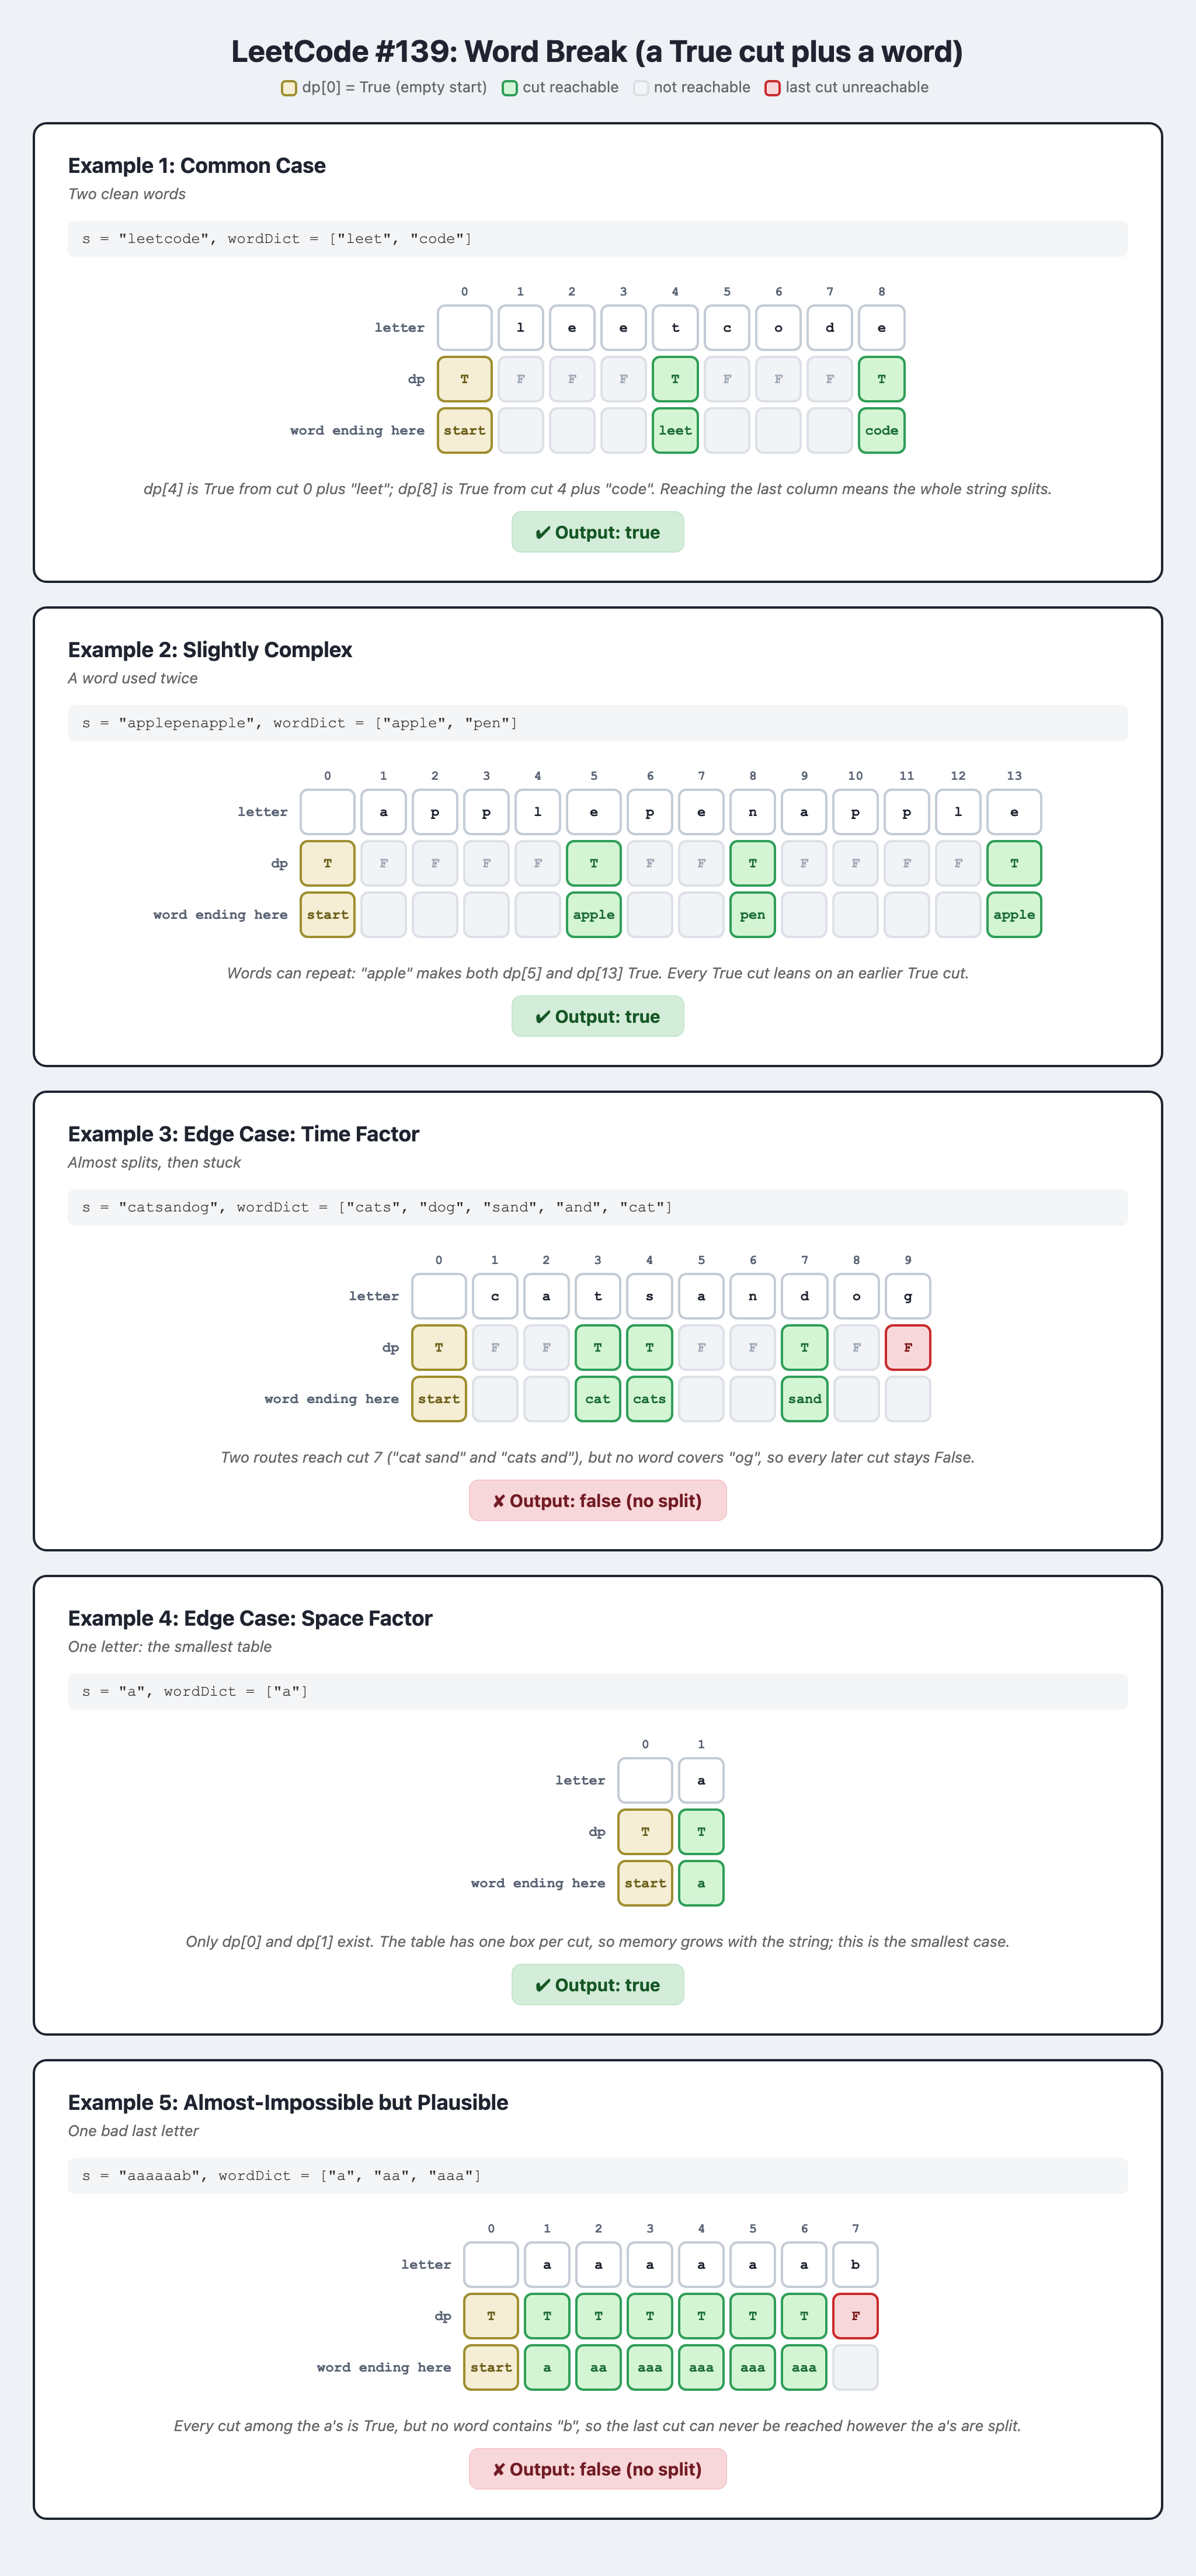

## Watch It Run

*Watch dp[7]: it becomes True from cut 3 plus "sand", and then every lookup for the last two letters fails, so the answer is False.*

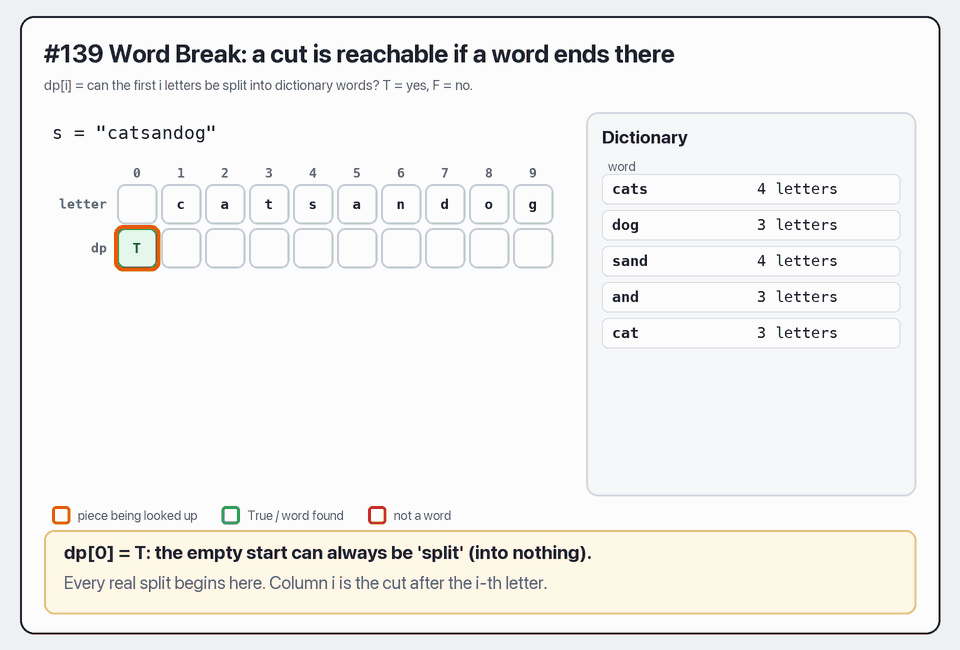